In [22]:
from sklearn.datasets import fetch_kddcup99
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import sklearn.cluster
from numpy.linalg import norm

In [23]:
kdd = fetch_kddcup99(subset=None, as_frame=True)

In [24]:
x=kdd.data.copy()
categorical_cols=["protocol_type","service","flag"]
numerical_cols=[]

for i in x.columns:
    if i not in categorical_cols:
        numerical_cols.append(i)


for col in numerical_cols:
    x[col]=pd.to_numeric(x[col],errors="raise").astype(np.float32)

x=pd.get_dummies(x,columns=categorical_cols,dtype=np.float32)
x=x.astype(np.float32,copy=False)

x=x.loc[:,x.nunique(dropna=False)>1]

mat=x.to_numpy(dtype=np.float32,copy=False)
mn=mat.min(axis=0)
mx=mat.max(axis=0)

D=(mat-mn)/(mx-mn)
D=D.astype(np.float32,copy=False)

n,d=D.shape

print("Number of rows (n):", n)
print("Number of columns (d):", d)
print("Shape of D:", D.shape)
print("Data type:", D.dtype)

Number of rows (n): 494021
Number of columns (d): 116
Shape of D: (494021, 116)
Data type: float32


PART(A)

In [25]:
random_state=0
cluster=15
start_time = time.time()
kmeans_a=sklearn.cluster.KMeans(n_clusters=cluster, random_state=42, n_init=5).fit(D)

num_of_samples=D.shape[0]
features=D.shape[1]

end_time = time.time()
execution_time_a = end_time - start_time
cost_ =0
for k in range(0,cluster):
  point_in_clust = D[kmeans_a.labels_ == k]
  mean = point_in_clust.mean(axis=0)
  for i in range(0,point_in_clust.shape[0]):
    cost_=cost_+(norm(point_in_clust[i]-mean)**2)




print("Cost(D, B):",cost_)
print("Execution time:", execution_time_a, "seconds")


Cost(D, B): 53497.5
Execution time: 14.166193723678589 seconds


PART(B, C and D)

######5#########
****** Iteration 1 ******
Execution time: 3.8604416847229004 seconds
Cost(D,B^): 60854.79296875
Cost(D,B*) 4307143.0
Ratio of Cost(D,B^)/Cost(D,B): 1.1375259
Ratio of Cost(D,B*)/Cost(D,B): 80.51111
****** Iteration 2 ******
Execution time: 3.184734582901001 seconds
Cost(D,B^): 62185.78125
Cost(D,B*) 4247237.5
Ratio of Cost(D,B^)/Cost(D,B): 1.1624054
Ratio of Cost(D,B*)/Cost(D,B): 79.39133
****** Iteration 3 ******
Execution time: 3.25127911567688 seconds
Cost(D,B^): 62377.97265625
Cost(D,B*) 4105152.0
Ratio of Cost(D,B^)/Cost(D,B): 1.1659979
Ratio of Cost(D,B*)/Cost(D,B): 76.7354
****** Iteration 4 ******
Execution time: 2.9218499660491943 seconds
Cost(D,B^): 56174.76953125
Cost(D,B*) 4226813.5
Ratio of Cost(D,B^)/Cost(D,B): 1.0500448
Ratio of Cost(D,B*)/Cost(D,B): 79.00955
****** Iteration 5 ******
Execution time: 2.596304178237915 seconds
Cost(D,B^): 64724.4375
Cost(D,B*) 4211724.0
Ratio of Cost(D,B^)/Cost(D,B): 1.2098591
Ratio of Cost(D,B*)/Cost(D,B): 78.72749
Avera

,m = 5,m = 10,m = 15,m = 20,m = 25
Metric,,,,,
Smallest Ratio,1.0500,0.9985,0.9692,0.9748,0.9577
Largest Ratio,1.2099,1.0877,1.0625,1.0448,1.0520
Average Ratio,1.1452,1.0467,1.0134,1.0098,1.0187


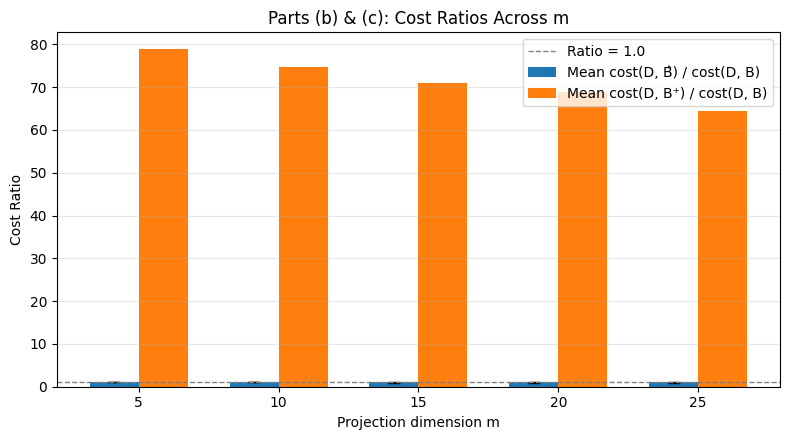

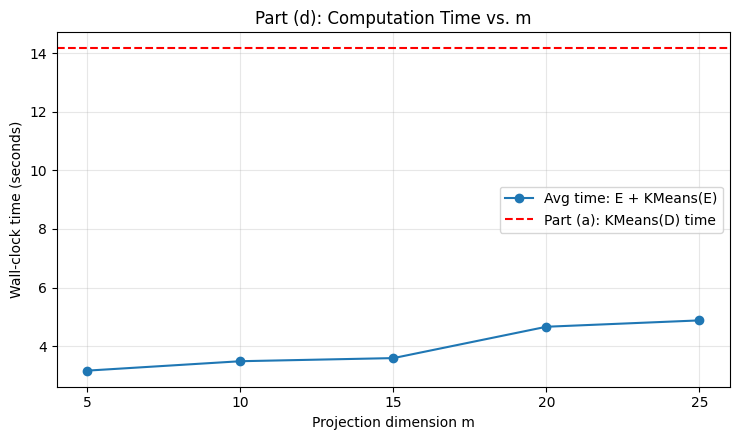

In [26]:
def cost_d_b_f(D, B):
  B = np.asarray(B, dtype=np.float32)
  d_sq = np.sum(D * D, axis=1, keepdims=True)
  b_sq = np.sum(B * B, axis=1, keepdims=True).T
  dist_sq = d_sq + b_sq - 2.0 * (D @ B.T)
  dist_sq = np.maximum(dist_sq, 0.0)
  return float(np.sum(np.min(dist_sq, axis=1)))

set_m = [5,10,15,20,25]
seeds = [0, 1, 2, 3, 4]
mean_ratio_b_hat, min_ratio_b_hat, max_ratio_b_hat = [], [], []
mean_ratio_b_plus, min_ratio_b_plus, max_ratio_b_plus = [], [], []
avg_times_m = []
for m in set_m:
    values_of_ration = []
    values_of_ratio2 = []
    time_of_computing = 0.0
    print(f"######{m}#########")
    for t in range(0,5):
      print(f"****** Iteration {t+1} ******")
      # we will draw A
      np.random.seed(seeds[t])
      dev=1/np.sqrt(m)
      start_time = time.time()
      A = np.random.normal(0,dev,(m,features))
      E = D @ A.T
      kmean = sklearn.cluster.KMeans(n_clusters=cluster, random_state=42, n_init=5).fit(E)
      end_time = time.time()
      execution_time = end_time - start_time
      time_of_computing += execution_time
      B_hat = np.zeros((cluster, features), dtype=D.dtype)
      for i in range(0, cluster):
              points = D[kmean.labels_ == i]
              if points.shape[0] > 0:
                B_hat[i] = points.mean(axis=0)
      A_pinv = np.linalg.pinv(A)
      B_plus = (kmean.cluster_centers_ @ A_pinv.T).astype(D.dtype)
      cost_d_b_dash = cost_d_b_f(D, B_hat)
      cost_d_b_star = cost_d_b_f(D, B_plus)
      print("Execution time:", execution_time, "seconds")
      print("Cost(D,B^):",cost_d_b_dash)
      print("Cost(D,B*)",cost_d_b_star)
      print("Ratio of Cost(D,B^)/Cost(D,B):",cost_d_b_dash/cost_)
      print("Ratio of Cost(D,B*)/Cost(D,B):",cost_d_b_star/cost_);
      values_of_ration.append(cost_d_b_dash/cost_)
      values_of_ratio2.append(cost_d_b_star/cost_)

    time_of_computing = time_of_computing/5

    print("Average time for computation:",time_of_computing,"seconds")
    print("Average Ratio for Cost(D,B^):",np.mean(values_of_ration))
    print("Smallest Ratio for Cost(D,B^):",np.min(values_of_ration))
    print("Largest Ratio for Cost(D,B^):",np.max(values_of_ration))
    print("Average Ratio for Cost(D,B*):",np.mean(values_of_ratio2))
    print("Smallest Ratio for Cost(D,B*):",np.min(values_of_ratio2))
    print("Largest Ratio for Cost(D,B*):",np.max(values_of_ratio2))
    mean_ratio_b_hat.append(np.mean(values_of_ration))
    min_ratio_b_hat.append(np.min(values_of_ration))
    max_ratio_b_hat.append(np.max(values_of_ration))
    mean_ratio_b_plus.append(np.mean(values_of_ratio2))
    min_ratio_b_plus.append(np.min(values_of_ratio2))
    max_ratio_b_plus.append(np.max(values_of_ratio2))
    avg_times_m.append(time_of_computing)

table_b = pd.DataFrame(
    {
        f"m = {m}": [min_val, max_val, mean_val]
        for m, min_val, max_val, mean_val in zip(
            set_m, min_ratio_b_hat, max_ratio_b_hat, mean_ratio_b_hat
        )
    },
    index=["Smallest Ratio", "Largest Ratio", "Average Ratio"],
)
table_b.index.name = "Metric"

print("\nPart (b): Ratio cost(D, B^) / cost(D, B) across m")
print(table_b.round(4).to_string())
display(table_b.round(4))

x_idx = np.arange(len(set_m))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x_idx - width / 2, mean_ratio_b_hat, width, label="Mean cost(D, B̂) / cost(D, B)")
ax.bar(x_idx + width / 2, mean_ratio_b_plus, width, label="Mean cost(D, B⁺) / cost(D, B)")

# Error bars showing min-to-max spread for B_hat across the 5 trials
yerr_hat = [
    np.array(mean_ratio_b_hat) - np.array(min_ratio_b_hat),
    np.array(max_ratio_b_hat) - np.array(mean_ratio_b_hat),
]
ax.errorbar(x_idx - width / 2, mean_ratio_b_hat, yerr=yerr_hat, fmt="none", ecolor="black", capsize=4)

ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="Ratio = 1.0")
ax.set_xticks(x_idx)
ax.set_xticklabels([str(m) for m in set_m])
ax.set_xlabel("Projection dimension m")
ax.set_ylabel("Cost Ratio")
ax.set_title("Parts (b) & (c): Cost Ratios Across m")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("parts_bc_ratios.png", dpi=200)
plt.show()


plt.figure(figsize=(7.5, 4.5))
plt.plot(set_m, avg_times_m, marker="o", label="Avg time: E + KMeans(E)")
plt.axhline(y=execution_time_a, color="red", linestyle="--", label="Part (a): KMeans(D) time")
plt.xlabel("Projection dimension m")
plt.ylabel("Wall-clock time (seconds)")
plt.title("Part (d): Computation Time vs. m")
plt.xticks(set_m)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("part_d_time.png", dpi=200)
plt.show()


PART(E)

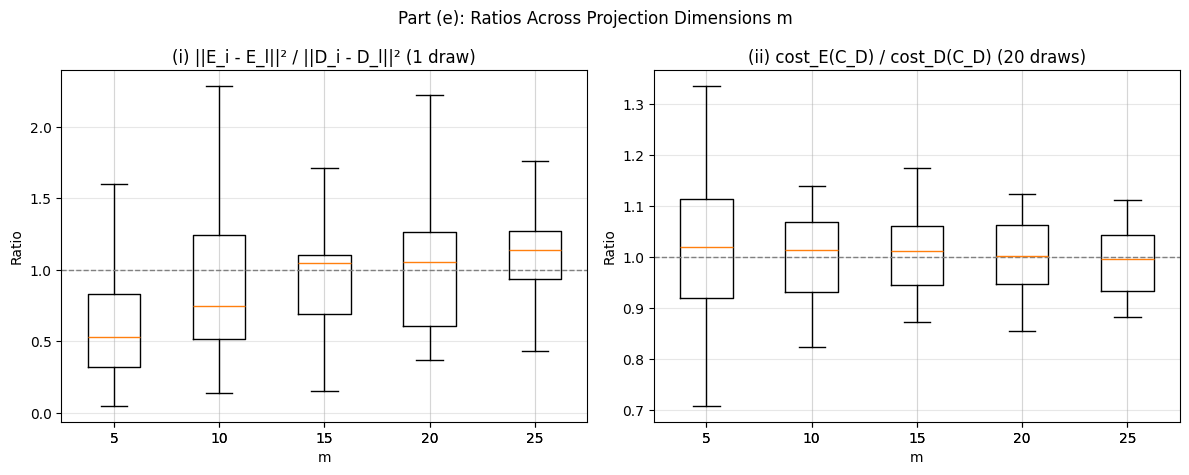

In [27]:
num_pairs = 10_000
np.random.seed(123)
pairs_i = []
pairs_l = []
seen = set()
while len(pairs_i) < num_pairs:
    cand_i = np.random.randint(0, n, size=num_pairs * 2)
    cand_l = np.random.randint(0, n, size=num_pairs * 2)
    for idx_i, idx_l in zip(cand_i, cand_l):
        i, l = int(idx_i), int(idx_l)
        if i == l or (i, l) in seen:
            continue
        if not np.array_equal(D[i], D[l]):
            seen.add((i, l))
            pairs_i.append(i)
            pairs_l.append(l)
            if len(pairs_i) == num_pairs:
                break

pairs_i = np.array(pairs_i)
pairs_l = np.array(pairs_l)

diff_D = D[pairs_i] - D[pairs_l]
denom_pairs = np.sum(diff_D ** 2, axis=1)

labels_D = kmeans_a.labels_
cost_D_CD = 0.0
for c in range(cluster):
    pts_D = D[labels_D == c]
    mu_D = pts_D.mean(axis=0)
    cost_D_CD += float(np.sum((pts_D - mu_D) ** 2))

pair_ratios_list = []


cluster_ratios_list = []
for m_idx in range(0,5):
    m = set_m[m_idx]
    dev = 1 / np.sqrt(m)
    np.random.seed(seeds[m_idx])
    A_one = np.random.normal(0,dev,(m,features))
    E_one=D @ A_one.T
    diff_E=E_one[pairs_i] - E_one[pairs_l]
    num_pairs_sq=np.sum(diff_E ** 2, axis=1)
    pair_ratios_list.append(num_pairs_sq/denom_pairs)
    c_ratios = []
    seed_new = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]
    for draw in range(20):
        np.random.seed(seed_new[draw])
        A_draw=np.random.normal(0,dev,(m, features))
        E_draw=D @ A_draw.T

        cost_E_CD=0.0
        for c in range(cluster):
            pts_E=E_draw[labels_D == c]
            if pts_E.shape[0]>0:
                mu_E=pts_E.mean(axis=0)
                cost_E_CD+=float(np.sum((pts_E - mu_E) ** 2))

        c_ratios.append(cost_E_CD/cost_D_CD)

    cluster_ratios_list.append(np.array(c_ratios))


fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)

axes[0].boxplot(pair_ratios_list, tick_labels=[str(m) for m in set_m], showfliers=False)
axes[0].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[0].set_title("(i) ||E_i - E_l||² / ||D_i - D_l||² (1 draw)")
axes[0].set_xlabel("m")
axes[0].set_ylabel("Ratio")
axes[0].grid(True, alpha=0.3)

axes[1].boxplot(cluster_ratios_list, tick_labels=[str(m) for m in set_m], showfliers=True)
axes[1].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("(ii) cost_E(C_D) / cost_D(C_D) (20 draws)")
axes[1].set_xlabel("m")
axes[1].set_ylabel("Ratio")
axes[1].grid(True, alpha=0.3)

plt.suptitle("Part (e): Ratios Across Projection Dimensions m")
plt.tight_layout()
plt.savefig("part_e_boxplots.png", dpi=200)
plt.show()